# 03 - Feature Engineering & Prototyping
**Project:** Sentinel Risk Engine  


### Objectives:
1. Engineer spatial features: Vectorized Haversine distance between customer home and merchant terminal.
2. Engineer cyclical temporal features: Trigonometric ($\sin/\cos$) embeddings for hour and day of week.
3. Engineer monetary features: Log-scale transformations ($\log_{1p}$).
4. Engineer behavioral velocity features: Leakage-safe rolling transaction counts and spending sums over sliding time windows (1-hour and 24-hour).
5. Audit and benchmark feature distributions against the target label (`is_fraud`).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (14, 5)

RAW_DATA_PATH = PROJECT_ROOT / "data" / "raw" / "fraudTrain.csv"
print(f"Loading data from: {RAW_DATA_PATH.resolve()}")

Loading data from: C:\Users\krish\OneDrive\Desktop\Sentinel-risk-engine\data\raw\fraudTrain.csv


In [2]:
df = pd.read_csv(RAW_DATA_PATH)

df = df.loc[:, ~df.columns.str.contains("^Unnamed")]

df["datetime"] = pd.to_datetime(df["trans_date_trans_time"])
df = df.sort_values("unix_time").reset_index(drop=True)

print("Dataset shape:", df.shape)
print("Time range:", df["datetime"].min(), "to", df["datetime"].max())

Dataset shape: (1296675, 23)
Time range: 2019-01-01 00:00:18 to 2020-06-21 12:13:37


In [4]:
def haversine_distance(lat1, lon1, lat2, lon2):
    R = 6371  # Earth radius in km

    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])

    a = (np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2)

    return 2 * R * np.arcsin(np.sqrt(np.clip(a, 0, 1)))


df["haversine_dist_km"] = haversine_distance(df["lat"], df["long"], df["merch_lat"], df["merch_long"])


print("Haversine Distance Summary (km):")
df["haversine_dist_km"].describe()

Haversine Distance Summary (km):


count    1.296675e+06
mean     7.611465e+01
std      2.911693e+01
min      2.225452e-02
25%      5.533491e+01
50%      7.823175e+01
75%      9.850327e+01
max      1.521172e+02
Name: haversine_dist_km, dtype: float64

In [5]:
hour = df["datetime"].dt.hour
dow = df["datetime"].dt.dayofweek

df["hour_sin"] = np.sin(2 * np.pi * hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * hour / 24)

df["dow_sin"] = np.sin(2 * np.pi * dow / 7)
df["dow_cos"] = np.cos(2 * np.pi * dow / 7)

df["is_weekend"] = dow.isin([5, 6]).astype(int)
df["log_amt"] = np.log1p(df["amt"])

df[["amt", "log_amt", "hour_sin", "hour_cos","dow_sin", "dow_cos", "is_weekend"]].head()

,amt,log_amt,hour_sin,hour_cos,dow_sin,dow_cos,is_weekend
0,4.97,1.786747,0.0,1.0,0.781831,0.62349,0
1,107.23,4.684259,0.0,1.0,0.781831,0.62349,0
2,220.11,5.398660,0.0,1.0,0.781831,0.62349,0
3,45.00,3.828641,0.0,1.0,0.781831,0.62349,0
4,41.96,3.760269,0.0,1.0,0.781831,0.62349,0


In [7]:
df = df.sort_values(["cc_num", "datetime"]).reset_index(drop=True)

for window in ["1h", "24h"]:
    counts = []
    sums = []

    for _, group in df.groupby("cc_num", sort=False):
        amounts = group.set_index("datetime")["amt"]

        counts.extend(amounts.rolling(window, closed="left").count().fillna(0).tolist())
        sums.extend(amounts.rolling(window, closed="left").sum().fillna(0).tolist())

    df[f"tx_count_{window}"] = counts
    df[f"tx_sum_{window}"] = sums

df = df.sort_values("unix_time").reset_index(drop=True)

df[["cc_num", "unix_time", "amt", "tx_count_1h","tx_sum_1h", "tx_count_24h", "tx_sum_24h"]].head(10)

,cc_num,unix_time,amt,tx_count_1h,tx_sum_1h,tx_count_24h,tx_sum_24h
0,2703186189652095,1325376018,4.97,0.0,0.0,0.0,0.0
1,630423337322,1325376044,107.23,0.0,0.0,0.0,0.0
2,38859492057661,1325376051,220.11,0.0,0.0,0.0,0.0
3,3534093764340240,1325376076,45.00,0.0,0.0,0.0,0.0
4,375534208663984,1325376186,41.96,0.0,0.0,0.0,0.0
5,4767265376804500,1325376248,94.63,0.0,0.0,0.0,0.0
6,30074693890476,1325376282,44.54,0.0,0.0,0.0,0.0
7,6011360759745864,1325376308,71.65,0.0,0.0,0.0,0.0
8,4922710831011201,1325376318,4.27,0.0,0.0,0.0,0.0
9,2720830304681674,1325376361,198.39,0.0,0.0,0.0,0.0


In [9]:
cols = ["tx_count_1h", "tx_sum_1h", "tx_count_24h", "tx_sum_24h"]

print("Nonzero values:")
print((df[cols] > 0).sum())

print("\nFeature summary:")
df[cols].describe()

Nonzero values:
tx_count_1h      212547
tx_sum_1h        212547
tx_count_24h    1187756
tx_sum_24h      1187756
dtype: int64

Feature summary:


,tx_count_1h,tx_sum_1h,tx_count_24h,tx_sum_24h
count,1.296675e+06,1.296675e+06,1.296675e+06,1.296675e+06
mean,1.895340e-01,1.455956e+01,3.884149e+00,2.752332e+02
std,4.617663e-01,9.658414e+01,3.082097e+00,4.235821e+02
min,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,0.000000e+00,0.000000e+00,2.000000e+00,6.667500e+01
50%,0.000000e+00,0.000000e+00,3.000000e+00,1.722500e+02
75%,0.000000e+00,0.000000e+00,5.000000e+00,3.445600e+02
max,6.000000e+00,2.739012e+04,3.500000e+01,2.977337e+04


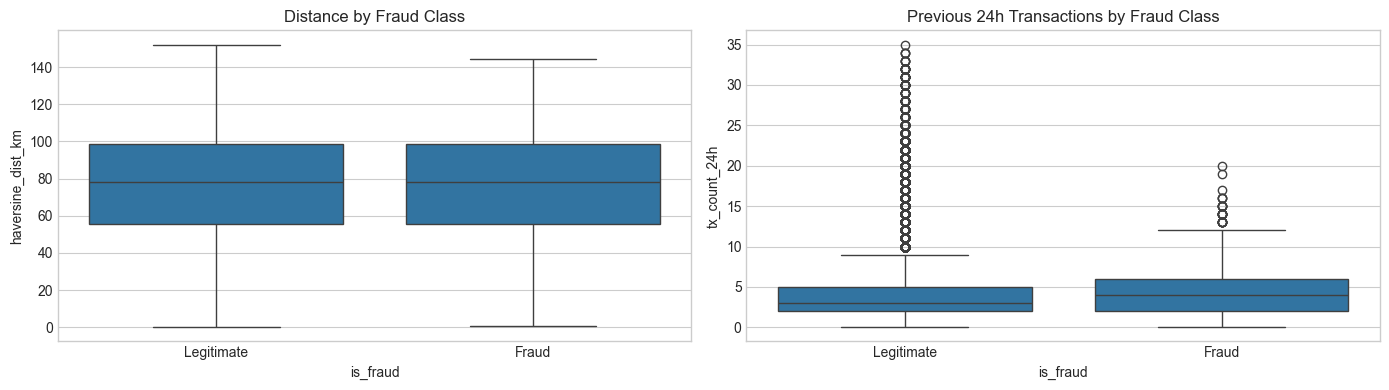

In [10]:
engineered_cols = [
    "amt", "log_amt", "haversine_dist_km",
    "hour_sin", "hour_cos", "dow_sin", "dow_cos",
    "tx_count_1h", "tx_sum_1h", "tx_count_24h", "tx_sum_24h"
]

corr = df[engineered_cols].corrwith(df["is_fraud"]).sort_values(ascending=False)

corr.to_frame("correlation_with_fraud")

fig, ax = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(data=df, x="is_fraud", y="haversine_dist_km", ax=ax[0])
ax[0].set_title("Distance by Fraud Class")
ax[0].set_xticks([0, 1], ["Legitimate", "Fraud"])

sns.boxplot(data=df, x="is_fraud", y="tx_count_24h", ax=ax[1])
ax[1].set_title("Previous 24h Transactions by Fraud Class")
ax[1].set_xticks([0, 1], ["Legitimate", "Fraud"])

plt.tight_layout()
plt.show()

## Summary 

1. Dataset loaded: Approximately 1.30 million transactions were loaded and sorted chronologically.
2. Spatial feature engineered: Haversine distance measures the geographic separation between cardholder and merchant coordinates.
3. Distance distribution: Median distance is approximately 78.23 km, with broadly similar distributions for legitimate and fraudulent transactions.
4. Cyclical hour encoding: Sine and cosine transformations represent the 24-hour cycle without treating midnight as far from 11 PM.
5. Cyclical weekday encoding: Sine and cosine features represent the recurring seven-day cycle.
6. Weekend indicator: is_weekend identifies Saturday and Sunday transactions.
7. Monetary transformation: log_amt compresses the transaction amount distribution and may help models handle skew.
8. Short-term velocity: One-hour transaction counts and spend capture recent cardholder activity.
9. Daily velocity: Twenty-four-hour counts and spend capture broader transaction behavior; the distributions overlap between classes, so predictive value must be tested.
10. Validation and versioning pending: Feature outputs have been generated in memory, but the processed dataset has not yet been saved or versioned with DVC.

# verify engineered value

In [11]:
# Check missing and infinite values
engineered_cols = [
    "haversine_dist_km", "hour_sin", "hour_cos",
    "dow_sin", "dow_cos", "is_weekend", "log_amt",
    "tx_count_1h", "tx_sum_1h", "tx_count_24h", "tx_sum_24h"
]

print("Missing values:")
print(df[engineered_cols].isna().sum())

print("\nInfinite values:")
print(np.isinf(df[engineered_cols]).sum())

print("\nFeature summary:")
df[engineered_cols].describe().T

Missing values:
haversine_dist_km    0
hour_sin             0
hour_cos             0
dow_sin              0
dow_cos              0
is_weekend           0
log_amt              0
tx_count_1h          0
tx_sum_1h            0
tx_count_24h         0
tx_sum_24h           0
dtype: int64

Infinite values:
haversine_dist_km    0
hour_sin             0
hour_cos             0
dow_sin              0
dow_cos              0
is_weekend           0
log_amt              0
tx_count_1h          0
tx_sum_1h            0
tx_count_24h         0
tx_sum_24h           0
dtype: int64

Feature summary:


,count,mean,std,min,25%,50%,75%,max
haversine_dist_km,1296675.0,76.114651,29.116935,0.022255,55.334913,7.823175e+01,98.503268,152.117173
hour_sin,1296675.0,-0.136689,0.693221,-1.000000,-0.866025,-2.588190e-01,0.500000,1.000000
hour_cos,1296675.0,-0.014060,0.707505,-1.000000,-0.707107,-1.836970e-16,0.707107,1.000000
dow_sin,1296675.0,-0.108690,0.684629,-0.974928,-0.781831,0.000000e+00,0.433884,0.974928
dow_cos,1296675.0,0.128513,0.709193,-0.900969,-0.222521,6.234898e-01,0.623490,1.000000
is_weekend,1296675.0,0.348226,0.476408,0.000000,0.000000,0.000000e+00,1.000000,1.000000
log_amt,1296675.0,3.533470,1.289448,0.693147,2.365560,3.881976e+00,4.432482,10.273322
tx_count_1h,1296675.0,0.189534,0.461766,0.000000,0.000000,0.000000e+00,0.000000,6.000000
tx_sum_1h,1296675.0,14.559564,96.584141,0.000000,0.000000,0.000000e+00,0.000000,27390.120000
tx_count_24h,1296675.0,3.884149,3.082097,0.000000,2.000000,3.000000e+00,5.000000,35.000000


## Verify rolling-feature correctness

In [12]:
# Check rolling features against historical transactions
sample = df.sample(100, random_state=42)
errors = 0

for _, row in sample.iterrows():
    history = df[
        (df["cc_num"] == row["cc_num"]) &
        (df["datetime"] < row["datetime"])
    ]

    for window, seconds in [("1h", 3600), ("24h", 86400)]:
        previous = history[
            history["datetime"] >= row["datetime"] - pd.Timedelta(seconds=seconds)
        ]

        count = len(previous)
        total = previous["amt"].sum()

        if count != row[f"tx_count_{window}"] or not np.isclose(
            total, row[f"tx_sum_{window}"]
        ):
            errors += 1

print("Sampled transactions checked:", len(sample))
print("Rolling-feature mismatches:", errors)

Sampled transactions checked: 100
Rolling-feature mismatches: 0


# saving procecssed dataset

In [13]:
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_PATH = PROCESSED_DIR / "fraud_features.parquet"

df.to_parquet(OUTPUT_PATH, index=False)

print("Dataset saved to:", OUTPUT_PATH)
print("Dataset shape:", df.shape)
print("File size (MB):", round(OUTPUT_PATH.stat().st_size / (1024 ** 2), 2))

Dataset saved to: C:\Users\krish\OneDrive\Desktop\Sentinel-risk-engine\data\processed\fraud_features.parquet
Dataset shape: (1296675, 34)
File size (MB): 126.52
